# 자연어 처리 2일차 (2) — 단어 빈도수 분석 · 워드클라우드 : 대한민국 헌법

수업 필기 `문서_마이닝` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `자연어처리` 교재9 p.41~43 — 단어 빈도수 분석 및 시각화 실습 · `Counter()` · `wordcloud`)

**흐름** : 한글 텍스트 → 형태소 분석기 → 형태소 토큰화 → **명사** 추출 → `Counter()` 빈도 → `WordCloud` 시각화

- Okt · Mecab 의 사용법 · 품사는 [`korean_morph_analyzers.ipynb`](./korean_morph_analyzers.ipynb)

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `konlpy` | **Okt** 형태소 분석기 · 헌법 말뭉치 `kolaw` | `pip install konlpy` — **Java(JDK)** 가 있어야 한다. Colab 은 기본 포함, Windows · Mac 은 JDK 설치 후 `JAVA_HOME` 설정 |
| `python-mecab-ko` | **Mecab** 형태소 분석기 (한국어 사전 포함) | `pip install python-mecab-ko` — 미리 만든 설치 파일이 없는 환경(예 : Python 3.13)에서는 직접 빌드하므로 리눅스 · Colab 에서 `apt-get install mecab libmecab-dev` 를 먼저 (필기와 같은 방법) |
| `kiwipiepy` | **Kiwi** 형태소 분석기 (비교용) | `pip install kiwipiepy` |
| `nltk` | `word_tokenize` · `RegexpTokenizer` | `pip install nltk` → 노트 안에서 `nltk.download('punkt_tab')` |
| `wordcloud` | 워드클라우드 | `pip install wordcloud` + **한글 폰트** (Colab : `apt-get install fonts-nanum`) |

**실행 순서** : ① 아래 설치 셀의 `#` 를 지우고 한 번 실행 (이미 설치돼 있으면 건너뜀) → ② 맨 위부터 **[런타임] → [모두 실행]** (셀을 건너뛰거나 거꾸로 실행하면 변수가 바뀐 채 남는다). 헌법 텍스트는 KoNLPy 에 들어 있어서 **따로 받을 파일이 없다**.

In [1]:
# ① 설치 (Colab · 처음 한 번)
# !apt-get install -y -qq mecab libmecab-dev fonts-nanum   # Mecab 빌드 도구 · 한글 폰트
# !pip install -q konlpy python-mecab-ko kiwipiepy nltk wordcloud

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 텍스트 불러오기

필기는 구글 드라이브의 `constitution.txt` 를 읽었다. 같은 헌법 전문이 **KoNLPy 에 예제 말뭉치로 들어 있어서** 그대로 쓴다(첫 줄 제목 `대한민국헌법` 은 필기 파일에 없어서 뺀다).

In [3]:
import warnings
warnings.filterwarnings('ignore')
from konlpy.corpus import kolaw

raw = kolaw.open('constitution.txt').read()
title, text = raw.split('\n', 1)
text = text.strip()
print('제목 :', title, '| 본문 글자 수 :', f'{len(text):,}')
print(text[:200], '\n...[중략]...')

제목 : 대한민국헌법 | 본문 글자 수 : 18,875
유구한 역사와 전통에 빛나는 우리 대한국민은 3·1운동으로 건립된 대한민국임시정부의 법통과 불의에 항거한 4·19민주이념을 계승하고, 조국의 민주개혁과 평화적 통일의 사명에 입각하여 정의·인도와 동포애로써 민족의 단결을 공고히 하고, 모든 사회적 폐습과 불의를 타파하며, 자율과 조화를 바탕으로 자유민주적 기본질서를 더욱 확고히 하여 정치·경제·사회·문화의  
...[중략]...


> **📝 고친 부분**
> - 드라이브 마운트 · `/content/drive/Othercomputers/...` 경로 → KoNLPy 내장 말뭉치 (직접 파일을 쓰려면 노트북과 같은 폴더의 `constitution.txt`)
> - 같은 파일을 **두 번** 읽고(`try` 셀 · 형태소 셀), `print("헌법:", text)` 로 1만 8천 자를 통째로 출력 → 한 번만 읽고 앞부분만 보기
> - 주석 `처음 5줄만 출력` 인데 코드는 `text[:5]`(**5글자**) — 줄 단위면 `text.splitlines()[:5]`

## 2. Okt 로 명사 추출 → 한 글자 걸러내기 → `Counter`

In [4]:
from collections import Counter
from konlpy.tag import Okt
from mecab import MeCab

okt, mecab = Okt(), MeCab()

nouns_okt = okt.nouns(text)
final_nouns = [n for n in nouns_okt if len(n) > 1]       # 두 글자 이상만
one_nouns = [n for n in nouns_okt if len(n) == 1]

count = Counter(final_nouns)
print(f'Okt 명사 {len(nouns_okt):,}개 → 두 글자 이상 {len(final_nouns):,}개 · 종류 {len(count):,}')
print('상위 15 :', count.most_common(15))
print()
print('한 글자 명사 상위 15 :', Counter(one_nouns).most_common(15))

Okt 명사 3,880개 → 두 글자 이상 3,011개 · 종류 850
상위 15 : [('법률', 127), ('대통령', 83), ('국가', 73), ('국회', 68), ('국민', 61), ('헌법', 52), ('모든', 37), ('기타', 26), ('사항', 23), ('권리', 21), ('의원', 21), ('자유', 20), ('정부', 20), ('선거', 20), ('임명', 20)]

한 글자 명사 상위 15 : [('제', 175), ('정', 89), ('수', 88), ('관', 58), ('때', 55), ('그', 47), ('이', 38), ('바', 37), ('위', 36), ('및', 25), ('안', 21), ('장', 15), ('인', 11), ('항', 8), ('것', 7)]


- 필기 출력과 같은 숫자(`법률` 127 · `대통령` 83 · 종류 **850**) → 같은 텍스트
- 한 글자 명사의 상위는 `제`(제1조의 '제') · `수`(할 수) · `정`(정한다) · `바`(정하는 바) · `때` — 대부분 **법조문 형식어**라 빼는 것이 맞다. 다만 `법` · `죄` 처럼 뜻 있는 한 글자도 함께 빠진다

> **📝 고친 부분** — `Counter` 를 `print` 하면 850개가 한 줄로 쏟아진다 → **`most_common(n)`** 으로 상위만

## 3. Mecab 으로 같은 작업 · Okt 와 비교

In [5]:
nouns_mecab = mecab.nouns(text)
count_mecab = Counter(n for n in nouns_mecab if len(n) > 1)
print(f'Mecab 명사 {len(nouns_mecab):,}개 · 두 글자 이상 종류 {len(count_mecab):,}')

import pandas as pd
top = pd.DataFrame({
    'Okt': [f'{w} {c}' for w, c in count.most_common(15)],
    'Mecab': [f'{w} {c}' for w, c in count_mecab.most_common(15)],
}, index=range(1, 16))
top

Mecab 명사 3,607개 · 두 글자 이상 종류 812


,Okt,Mecab
1,법률 127,법률 121
2,대통령 83,대통령 84
3,국가 73,국가 73
4,국회 68,국민 69
5,국민 61,국회 69
6,헌법 52,헌법 68
7,모든 37,필요 31
8,기타 26,위원 30
9,사항 23,기타 26
10,권리 21,법원 25


In [6]:
only_okt = sorted(set(count) - set(count_mecab), key=lambda w: -count[w])
only_mecab = sorted(set(count_mecab) - set(count), key=lambda w: -count_mecab[w])
print('Okt 에만 있는 명사 (빈도 순) :', [(w, count[w]) for w in only_okt[:20]])
print()
print('Mecab 에만 있는 명사 (빈도 순) :', [(w, count_mecab[w]) for w in only_mecab[:20]])

Okt 에만 있는 명사 (빈도 순) : [('모든', 37), ('국무위원', 17), ('항의', 14), ('헌법재판소', 14), ('거나', 13), ('다만', 11), ('대한', 10), ('안전보장', 10), ('대하', 9), ('상의', 8), ('지방자치단체', 7), ('국민투표', 7), ('로써', 5), ('군사법원', 4), ('재산권', 4), ('로서', 4), ('로부터', 4), ('후임', 4), ('정은', 3), ('행정기관', 3)]

Mecab 에만 있는 명사 (빈도 순) : [('국무', 23), ('재판소', 14), ('대법원장', 10), ('지방', 9), ('선거관리위원회', 7), ('법률안', 7), ('소추', 6), ('특별', 6), ('회기', 6), ('각급', 5), ('후임자', 4), ('중립', 3), ('불리', 3), ('연임', 3), ('현행범', 3), ('균등', 3), ('각부', 2), ('안녕질서', 2), ('포고', 2), ('후보', 2)]


- Okt 에만 있는 상위 '명사' 중 `거나` · `대하` · `로써` · `상의` · `로부터` · `대한` 은 **어미 · 조사 조각**, `모든` 은 관형사, `항의`(14)는 '제1**항의**' 의 `항 + 의` 를 명사 '항의(抗議)' 로 잘못 붙인 것 → Okt 결과는 **불용어 정리**가 필요
- 복합 명사를 자르는 기준도 다르다 — Okt 는 `국무위원` · `헌법재판소` 를 한 단어로, Mecab 은 `국무` + `위원` · `헌법` + `재판소` 로 나눈다(그래서 Mecab 의 `헌법` 52 → 68 · `위원` 10 → 30). 반대로 `선거관리위원회` · `대법원장` 은 Mecab 만 한 단어로 둔다
- 같은 글이라도 **분석기에 따라 빈도 순위가 달라진다** — 결과를 보고 분석기 · 사용자 사전을 고르는 것도 분석의 일부

## 4. 불용어 걸러 내기 · 상위 단어 막대그래프

![빈도 누적 애니메이션](./images/anim_03_counter_race.gif)

불용어 제거 후 종류 : 826


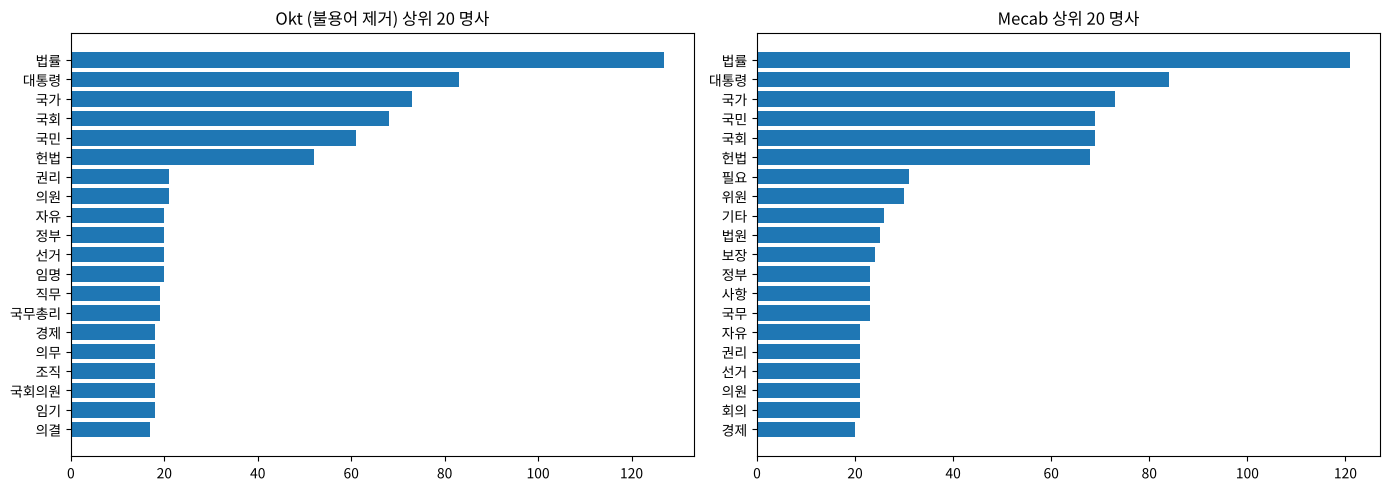

In [7]:
stopwords = {'거나', '대하', '로써', '로부터', '로서', '상의', '대한', '정은', '자가', '당한', '인의', '하의', '항의',
             '다만', '모든', '기타', '사항', '경우', '이상', '이하', '이내', '누구', '또한', '다음'}
clean = Counter({w: c for w, c in count.items() if w not in stopwords})
print('불용어 제거 후 종류 :', len(clean))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, c) in zip(axes, [('Okt (불용어 제거)', clean), ('Mecab', count_mecab)]):
    words, freqs = zip(*c.most_common(20))
    ax.barh(words[::-1], freqs[::-1], color='tab:blue')
    ax.set_title(f'{name} 상위 20 명사')
plt.tight_layout(); plt.show()

## 5. 📝 `str.find` 로 센 '법률' 은 몇 번?

필기는 `find` 반복으로 '법률' 을 세면서 `index = text.find(text)` 로 시작했다.

In [8]:
target = '법률'

# 필기 코드 그대로
cout = 0
index = text.find(text)            # 텍스트 자기 자신을 찾으면 항상 0 → '법률' 위치가 아닌데도 1번 센다
while index != -1:
    cout += 1
    index = text.find(target, index + 1)
print('필기 코드          :', cout)

# 고친 코드
cnt, index = 0, text.find(target)
while index != -1:
    cnt += 1
    index = text.find(target, index + 1)
print('find 반복 (고침)   :', cnt, '| text.count :', text.count(target))
print('Okt 명사 \'법률\'     :', count[target], '| Mecab :', count_mecab[target])

import re
after = Counter(text[m.end()] for m in re.finditer(target, text))
print('\'법률\' 바로 뒤 글자 :', after.most_common(6))

필기 코드          : 129
find 반복 (고침)   : 128 | text.count : 128
Okt 명사 '법률'     : 127 | Mecab : 121
'법률' 바로 뒤 글자 : [('이', 60), ('로', 35), ('에', 12), ('안', 9), ('의', 5), ('을', 3)]


- 필기 코드는 시작점이 '법률' 위치가 아니라 0 이라 **1번 더 센다**(129). `text.find(target)` 으로 시작하거나 `text.count(target)` 한 줄이면 **128**
- 글자열 찾기(128)와 명사 수(Okt 127 · Mecab 121)가 다른 이유 : `법률안`(9번) · `법률상` 처럼 **다른 단어 안의 '법률'** 도 글자열로는 세어지고, 분석기는 이것을 `법률안` 한 단어 또는 다른 형태소로 본다 → '단어 빈도' 는 **토큰화한 뒤** 세야 한다

## 6. 워드클라우드 (교재 p.43)

사용 순서 : ① 임포트 ② **한글 폰트** 지정 ③ `WordCloud` 객체 생성 ④ 이미지 생성 ⑤ 저장 ⑥ 출력

폰트 : NotoSansCJK-Black.ttc


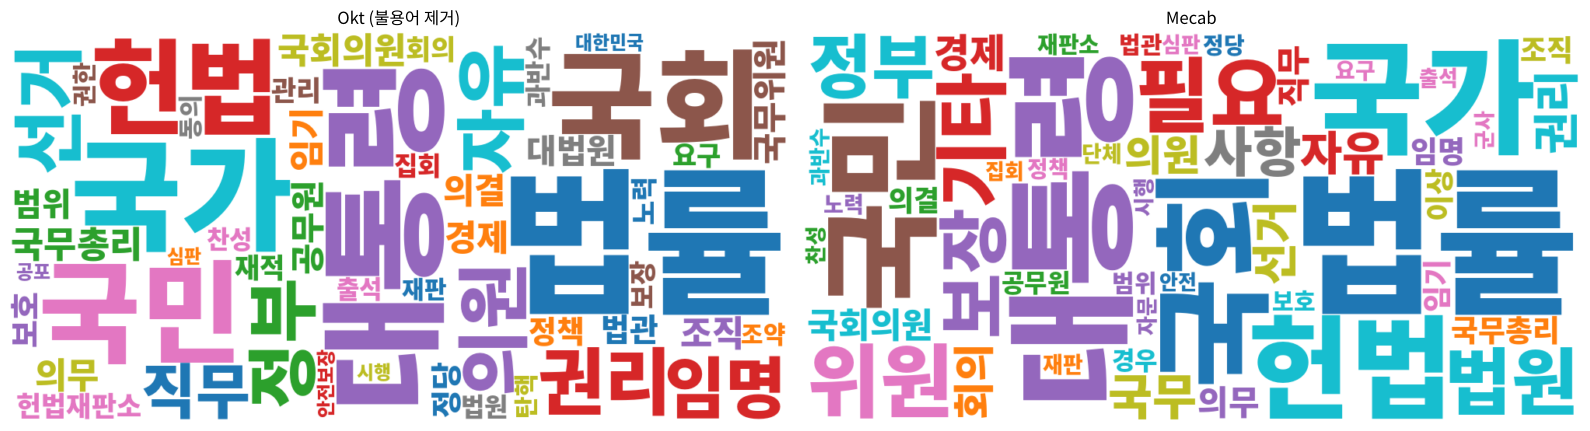

In [9]:
import os
import matplotlib.font_manager as fm
from wordcloud import WordCloud

# ② 한글 폰트 경로 찾기 (Colab : !apt-get install fonts-nanum 후 NanumBarunGothic)
candidates = ['/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf', 'C:/Windows/Fonts/malgun.ttf',
              '/System/Library/Fonts/Supplemental/AppleGothic.ttf']
font = next((p for p in candidates if os.path.exists(p)), None) or \
       next(f for f in fm.findSystemFonts() if 'NotoSansCJK' in f or 'Nanum' in f)
print('폰트 :', os.path.basename(font))

def make_cloud(freq, path):
    wc = WordCloud(font_path=font, width=1000, height=500, max_words=50, max_font_size=200,
                   background_color='white', colormap='tab10', random_state=0)     # ③
    wc.generate_from_frequencies(freq)                                           # ④ 빈도 딕셔너리로
    wc.to_file(path)                                                             # ⑤
    return wc

wc_okt = make_cloud(clean, 'wordcloud_okt.png')
wc_mecab = make_cloud(count_mecab, 'wordcloud_mecab.png')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))                                # ⑥
for ax, wc, name in zip(axes, [wc_okt, wc_mecab], ['Okt (불용어 제거)', 'Mecab']):
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(name)
plt.tight_layout(); plt.show()

![워드클라우드 애니메이션](./images/anim_04_wordcloud_build.gif)

> **📝 고친 부분** (필기 `문서_마이닝` · 교재 p.43)
> - 폰트 `NanumBarunGothic-YetHangul.ttf` → 옛한글 글자까지 담은 변형 파일이라 동작은 하지만, 설치된 나눔 폰트 버전에 따라 파일 이름이 다를 수 있다 → 경로를 하나로 박아 두기보다 위처럼 **있는 한글 폰트를 찾아서** 지정
> - 이미지를 드라이브에 저장만 하고 **화면 출력(⑥)이 없었다** → `plt.imshow(wc)` 추가
> - `wc.generate_from_frequencies(count)` 에 불용어가 섞인 `count` 를 그대로 → 정리한 빈도(`clean`) 사용
> - 교재 p.43 `WordClod` → **WordCloud**

![불용어 단계 애니메이션](./images/anim_05_stopword_steps.gif)

## 📝 고친 부분 정리 (필기 `문서_마이닝`)

| 원본 | 고친 것 |
|---|---|
| 드라이브 경로 · 같은 파일 두 번 읽기 · 전문 출력 | KoNLPy 내장 헌법 · 한 번 읽기 · 앞부분만 |
| 주석 '처음 5줄' · 코드 `text[:5]` | 5글자 — 줄이면 `splitlines()[:5]` |
| `index = text.find(text)` 로 '법률' 세기 → 129 | `text.find(target)` 시작 · `text.count` → 128, 단어 빈도는 토큰화 후(127 / 121) |
| `Counter` 전체 출력 | `most_common(n)` |
| Okt 명사 그대로 빈도 | 조사 · 어미 조각(거나 · 대하 · 로써 …) 불용어 제거 |
| 변수 `mecap` · `output1` 재사용 | `mecab` · `nouns_okt` / `nouns_mecab` |
| 폰트 `NanumBarunGothic-YetHangul` · 출력 없음 | 있는 한글 폰트 찾기 · `imshow` 로 출력 |